## BASELINE MODELS

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate
)

from sklearn.svm import SVC

from sklearn.ensemble import RandomForestClassifier

from sklearn.dummy import DummyClassifier


In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

processed_path = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "primary_532nm_features.npz"
)

data = np.load(processed_path)

X_max = data["X_max"]
X_l2 = data["X_l2"]
X_area = data["X_area"]

grid = data["raman_grid"]

mineral = data["mineral"]
rruff_id = data["rruff_id"]

feature_metadata = pd.DataFrame({
    "mineral": mineral,
    "rruff_id": rruff_id
})

print("Original feature matrix:", X_l2.shape)
print("Number of minerals:", feature_metadata["mineral"].nunique())
print("Unique sample IDs:", feature_metadata["rruff_id"].nunique())

Original feature matrix: (137, 1991)
Number of minerals: 12
Unique sample IDs: 137


In [3]:
split_path = (
    PROJECT_ROOT
    / "data"
    / "manifests"
    / "primary_532nm_split_assignment.csv"
)

split_assignment = pd.read_csv(split_path)

print(split_assignment["split"].value_counts())

split
train          82
test           28
calibration    27
Name: count, dtype: int64


In [4]:
train_ids = set(
    split_assignment.loc[
        split_assignment["split"] == "train",
        "rruff_id"
    ]
)

train_mask = feature_metadata["rruff_id"].isin(train_ids).to_numpy()

X_train = {
    "Maximum": X_max[train_mask],
    "L2": X_l2[train_mask],
    "Area": X_area[train_mask]
}

meta_train = (
    feature_metadata.loc[train_mask]
    .reset_index(drop=True)
)

y_train = meta_train["mineral"].to_numpy()

groups_train = meta_train["rruff_id"].to_numpy()

print("Training observations:", len(y_train))
print("Training classes:", len(np.unique(y_train)))
print("Training sample IDs:", len(np.unique(groups_train)))

Training observations: 82
Training classes: 12
Training sample IDs: 82


In [5]:
assert all(
    matrix.shape == (82, 1991)
    for matrix in X_train.values()
)

assert len(y_train) == 82

assert len(np.unique(y_train)) == 12

assert len(np.unique(groups_train)) == 82

assert all(
    np.isfinite(matrix).all()
    for matrix in X_train.values()
)

assert set(groups_train) == train_ids

## 1. Create the classifiers

#### LINEAR SVM

In [6]:
linear_svm = SVC(
    kernel="linear",
    C=1.0,
    class_weight="balanced"
)

#### RBF SVM

In [7]:
rbf_svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight="balanced"
)

#### RANDOM FORESTS

In [8]:
random_forest = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

#### DUMMY CLASSIFIER

In [9]:
dummy = DummyClassifier(
    strategy="most_frequent"
)

In [10]:
models = {
    "Dummy": dummy,
    "Linear SVM": linear_svm,
    "RBF SVM": rbf_svm,
    "Random Forest": random_forest
}

### 1.2 Five fold cross-validation

In [17]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [18]:
scoring = {
    "macro_f1": "f1_macro",
    "balanced_accuracy": "balanced_accuracy",
    "accuracy": "accuracy"
}

In [19]:
results = []

for normalization_name, X in X_train.items():

    print(f"\nNormalisation: {normalization_name}")

    for model_name, model in models.items():

        print(f"  Evaluating: {model_name}")

        cv_result = cross_validate(
            estimator=model,
            X=X,
            y=y_train,
            groups=groups_train,
            cv=cv,
            scoring=scoring,
            return_train_score=True,
            n_jobs=1,
            error_score="raise"
        )

        results.append({

            "normalization": normalization_name,

            "model": model_name,

            "train_macro_f1_mean":
                cv_result["train_macro_f1"].mean(),

            "validation_macro_f1_mean":
                cv_result["test_macro_f1"].mean(),

            "validation_macro_f1_std":
                cv_result["test_macro_f1"].std(ddof=1),

            "validation_balanced_accuracy_mean":
                cv_result["test_balanced_accuracy"].mean(),

            "validation_balanced_accuracy_std":
                cv_result["test_balanced_accuracy"].std(ddof=1),

            "validation_accuracy_mean":
                cv_result["test_accuracy"].mean(),

            "validation_accuracy_std":
                cv_result["test_accuracy"].std(ddof=1)
        })


Normalisation: Maximum
  Evaluating: Dummy
  Evaluating: Linear SVM
  Evaluating: RBF SVM
  Evaluating: Random Forest

Normalisation: L2
  Evaluating: Dummy
  Evaluating: Linear SVM
  Evaluating: RBF SVM
  Evaluating: Random Forest

Normalisation: Area
  Evaluating: Dummy
  Evaluating: Linear SVM
  Evaluating: RBF SVM
  Evaluating: Random Forest


In [20]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "validation_macro_f1_mean",
    ascending=False
).reset_index(drop=True)

display(
    results_df.round(3)
)

,normalization,model,train_macro_f1_mean,validation_macro_f1_mean,validation_macro_f1_std,validation_balanced_accuracy_mean,validation_balanced_accuracy_std,validation_accuracy_mean,validation_accuracy_std
0,Maximum,Random Forest,1.000,0.922,0.063,0.933,0.063,0.940,0.042
1,L2,Random Forest,1.000,0.922,0.063,0.933,0.063,0.940,0.042
2,Area,Random Forest,1.000,0.922,0.063,0.933,0.063,0.940,0.042
3,Maximum,Linear SVM,0.970,0.919,0.052,0.942,0.037,0.939,0.044
4,Area,RBF SVM,0.932,0.908,0.088,0.933,0.063,0.926,0.082
5,Maximum,RBF SVM,0.920,0.908,0.088,0.933,0.063,0.926,0.082
6,L2,RBF SVM,0.927,0.908,0.088,0.933,0.063,0.926,0.082
7,L2,Linear SVM,0.927,0.908,0.088,0.933,0.063,0.926,0.082
8,Area,Linear SVM,0.267,0.278,0.200,0.383,0.209,0.381,0.175
9,Maximum,Dummy,0.016,0.013,0.005,0.083,0.000,0.085,0.033


In [21]:
reports_dir = PROJECT_ROOT / "reports"

reports_dir.mkdir(exist_ok=True)

results_df.to_csv(
    reports_dir / "baseline_cv_results.csv",
    index=False
)

### 1.3 Visualise the baseline comparison

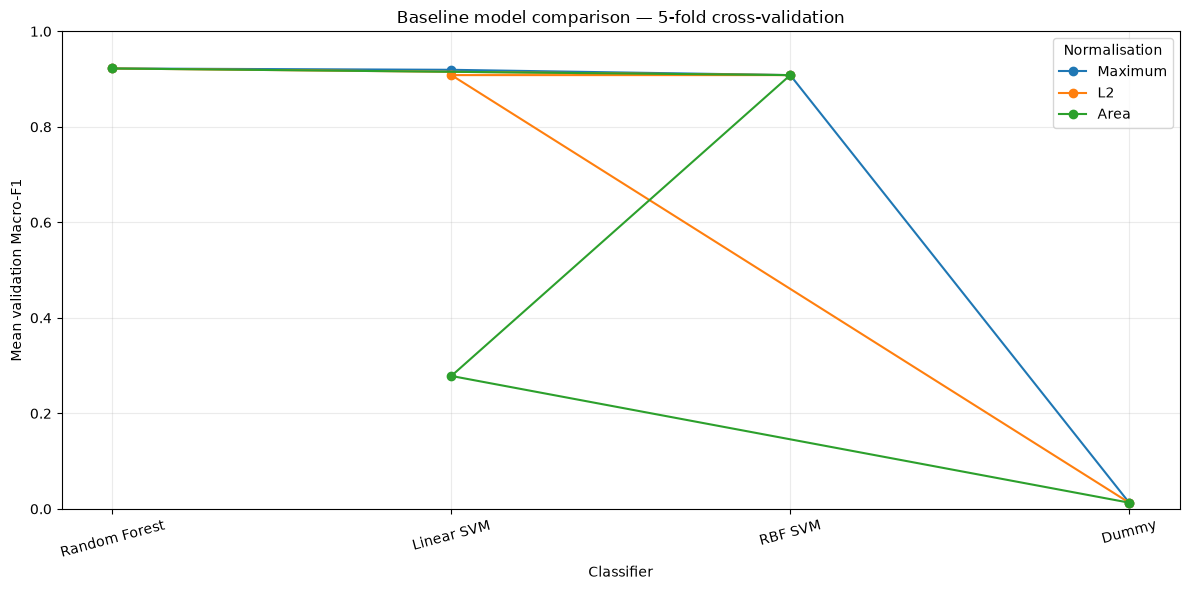

In [22]:
fig, ax = plt.subplots(figsize=(12, 6))

for normalization_name in ["Maximum", "L2", "Area"]:

    subset = results_df[
        results_df["normalization"] == normalization_name
    ]

    subset = subset.set_index("model")

    ax.plot(
        subset.index,
        subset["validation_macro_f1_mean"],
        marker="o",
        linewidth=1.5,
        label=normalization_name
    )

ax.set_title(
    "Baseline model comparison — 5-fold cross-validation"
)

ax.set_ylabel("Mean validation Macro-F1")

ax.set_xlabel("Classifier")

ax.set_ylim(0, 1)

ax.grid(alpha=0.25)

ax.legend(title="Normalisation")

plt.xticks(rotation=15)

plt.tight_layout()

fig.savefig(
    reports_dir / "baseline_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()